# 13 - Full Desk

Every factor → single decision.


## Setup

In [1]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\\Projects\\done\\eth_bot\\eth_bot_v2")
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
np.random.seed(42)

SYMBOL = "ETHUSDT"
OUT = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "reports" / "forecasts"
OUT.mkdir(parents=True, exist_ok=True)
DB = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "database" / "market.db"

def sql(q, **p):
    with sqlite3.connect(DB) as c:
        return pd.read_sql_query(q, c, params=p)

from database.config.api.binance import get_klines

def fetch(symbol, interval, limit=500):
    raw = get_klines(symbol, interval=interval, limit=limit)
    df = pd.DataFrame(raw, columns=["open_time","open","high","low","close",
        "volume","close_time","quote_volume","trades","taker_base","taker_quote","ignore"])
    df["date"] = pd.to_datetime(df["open_time"], unit="ms", utc=True).dt.tz_convert(None)
    for c in ("open","high","low","close","volume"):
        df[c] = df[c].astype(float)
    return df[["date","open","high","low","close","volume"]].set_index("date").iloc[:-1]

def action_block(name, action, reason, price=None, entry=None, stop=None,
                 target=None, conf=None, extra=None):
    print("=" * 62)
    print(f"  {name}")
    print("=" * 62)
    print(f"  time   : {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M')} UTC")
    if price is not None: print(f"  price  : {price:,.2f}")
    if conf  is not None: print(f"  conf   : {conf:.2f}")
    print(f"  ACTION : {action}")
    print(f"  REASON : {reason}")
    if entry is not None:
        print(f"  entry  : {entry:,.2f}   stop: {stop:,.2f}   target: {target:,.2f}")
    if extra:
        for k, v in extra.items():
            print(f"  {k:<6} : {v}")
    print("=" * 62)
    return {"action": action, "reason": reason, "price": price,
            "entry": entry, "stop": stop, "target": target, "conf": conf}

## 1. Fetch

In [2]:
eth = fetch("ETHUSDT", "1d", 500)
from analysis.indicators import add_all
d = add_all(eth).dropna()
print("price:", d.close.iloc[-1])

price: 2687.23


## 2. All signals

In [3]:
signals = {}
last = d.iloc[-1]

signals["trend"]    = 1 if last.close > last.sma_50 else -1
signals["rsi"]      = 1 if last.rsi_14 < 30 else (-1 if last.rsi_14 > 70 else 0)
signals["macd"]     = 1 if last.macd_hist > 0 else -1
signals["momentum"] = 1 if d.close.pct_change(20).iloc[-1] > 0 else -1

try:
    fg = sql("SELECT value FROM fear_greed ORDER BY ts DESC LIMIT 1")["value"].iloc[0]
    signals["fng"] = 1 if fg < 20 else (-1 if fg > 80 else 0)
except: signals["fng"] = 0

try:
    fr = sql("SELECT rate FROM funding_rate ORDER BY ts DESC LIMIT 1")["rate"].iloc[0]
    signals["funding"] = -1 if fr > 0.001 else (1 if fr < -0.001 else 0)
except: signals["funding"] = 0

for k, v in signals.items():
    print(f"  {k:<12} {v:+d}")

  trend        +1
  rsi          +0
  macd         -1
  momentum     +1
  fng          +0
  funding      +0


## 3. Visual

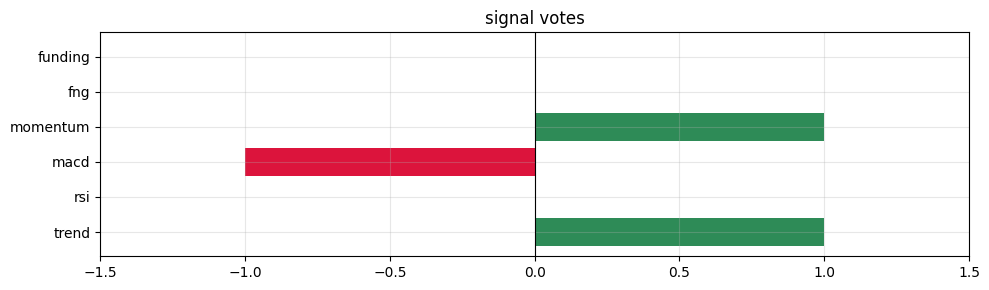

In [4]:
fig, ax = plt.subplots(figsize=(10, 3))
names = list(signals.keys())
vals = list(signals.values())
colors = ["seagreen" if v>0 else "crimson" if v<0 else "gray" for v in vals]
ax.barh(names, vals, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-1.5, 1.5)
ax.set_title("signal votes")
plt.tight_layout(); plt.show()

## 4. Score

In [5]:
score = sum(signals.values())
max_score = len(signals)
print(f"score: {score:+d} / {max_score}")

score: +1 / 6


## 5. Confidence

In [6]:
conf = abs(score) / max_score
print(f"confidence: {conf:.2f}")

confidence: 0.17


## 6. Trend filter override

In [7]:
trend_ok = last.close > last.sma_50
if score > 0 and not trend_ok:
    print("up signal but downtrend -> downgrade")
    score = 0
elif score < 0 and trend_ok:
    print("down signal but uptrend -> downgrade")
    score = 0

## 7. Position sizing

In [8]:
ACCOUNT = 1000.0
RISK_PCT = 1.0
atr = float(last.atr_14)
stop_dist = 1.5 * atr
entry = float(last.close)
risk_usd = ACCOUNT * RISK_PCT / 100
size = risk_usd / stop_dist

## 8. Compose final

In [9]:
if score >= 3:
    action = "LONG"
    stop, target = entry - stop_dist, entry + 2*stop_dist
    reason = f"{score} bullish signals + uptrend"
elif score <= -3:
    action = "SHORT"
    stop, target = entry + stop_dist, entry - 2*stop_dist
    reason = f"{score} bearish signals + downtrend"
else:
    action = "FLAT"
    stop = target = entry
    reason = f"weak signal ({score})"
    size = 0

print(f"action: {action}")

action: FLAT


## 9. Risk warnings

In [10]:
warn = []
if conf < 0.3: warn.append("low confidence")
if abs(score) < 3: warn.append("weak composite")
if atr/entry > 0.05: warn.append("high ATR — size down")
for w in warn: print(" !", w)
if not warn: print(" no warnings")

 ! low confidence
 ! weak composite


## 10. Final action block

In [11]:
sig = action_block("ETH FULL DESK", action, reason,
    price=entry, conf=conf,
    entry=entry, stop=stop, target=target,
    extra={"size": f"{size:.4f} ETH", "risk": f"${risk_usd:.2f}"})

ts = datetime.now(timezone.utc).strftime("%Y-%m-%d_%H%M")
(OUT/f"trade_full_{ts}.json").write_text(json.dumps(sig, indent=2, default=str))
print("wrote", OUT/f"trade_full_{ts}.json")

  ETH FULL DESK
  time   : 2026-10-04 10:49 UTC
  price  : 2,687.23
  conf   : 0.17
  ACTION : FLAT
  REASON : weak signal (1)
  entry  : 2,687.23   stop: 2,687.23   target: 2,687.23
  size   : 0.0000 ETH
  risk   : $10.00
wrote D:\Projects\done\eth_bot\eth_bot_v2\reports\forecasts\trade_full_2026-10-04_1049.json


## 11. One-line summary

In [12]:
if action == "FLAT":
    line = f"FLAT  |  {reason}  |  conf {conf:.2f}"
else:
    line = f"{action}  |  entry {entry:.2f}  stop {stop:.2f}  target {target:.2f}  |  conf {conf:.2f}"
print()
print(">>>", line)
print()
print("END OF RUN")


>>> FLAT  |  weak signal (1)  |  conf 0.17

END OF RUN
